In [1]:
import pandas as pd
import scipy.stats
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
from collections import Counter
import torch
import os
import sys
from BWM.models.isometric_autoencoder import get_density_proxy
# Add project root to path
sys.path.append(os.path.abspath('../../'))
import torch.optim as optim
from BWM.bwm_functions import *
from BWM.models.isometric_autoencoder import SklearnIsometricAutoencoder

plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

# Set global plotting parameters for font size
tick_fontsize = 6
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': tick_fontsize,
    'ytick.labelsize': tick_fontsize,
    'legend.fontsize': 7,
    'figure.titlesize': 7
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cpu


In [13]:
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset

# # Recurrent neural network model for fitting neural responses
class RNN(torch.nn.Module):
    def __init__(self, n, input_dim,beta,bias):
        super(RNN, self).__init__()

        self.n = n
        self.input_dim = input_dim
        self.beta = beta
        self.bias = bias

        self.activation = torch.nn.Softplus(beta =self.beta)
        # Hidden dynamics
        self.recurrent_layer = nn.Linear(self.n, self.n, bias=True)
        self.recurrent_layer.bias.data.normal_(mean=self.bias, std=0)
        self.recurrent_layer.bias.requires_grad = True

    # Dynamics

    def forward(self, dt, steps):
        batch_size = 1
        states = torch.zeros(batch_size, 1, self.n, device=device)
        for i in range(steps - 1):
            state_new = (1 - dt) * states[:, i, :] + dt * (
                self.activation(self.recurrent_layer(states[:, i, :]) ))
            states = torch.cat((states, state_new.unsqueeze_(1)), 1)

        return states



In [14]:
def get_density(x, k=50):
    """
    Computes the average k-NN distance in the input space as a proxy for inverse density.
    """
    if isinstance(x, np.ndarray):
        x = torch.FloatTensor(x)

    batch_size = x.shape[0]
    k = min(k, batch_size - 1)

    # We might need to do this in batches if x is very large
    if batch_size > 2000:
        avg_dists = []
        for i in range(0, batch_size, 1000):
            batch_x = x[i:i+1000]
            # Compute distances from batch to all points
            dists = torch.cdist(batch_x, x)
            knn_dist, _ = torch.topk(dists, k + 1, largest=False)
            avg_dists.append(knn_dist[:, 1:].mean(dim=1))
        return torch.cat(avg_dists, dim=0)
    else:
        x_dist = torch.cdist(x, x)
        x_knn_dist, _ = torch.topk(x_dist, k + 1, largest=False)
        return x_knn_dist[:, 1:].mean(dim=1)


import torch

def differentiable_pearson_correlation(x, y):
    """
    Computes the differentiable Pearson correlation coefficient between two 1D tensors.

    Parameters:
    -----------
    x, y : torch.Tensor
        1D tensors of the same length (N,)

    Returns:
    --------
    pearson_corr : torch.Tensor
        A scalar tensor between -1 and 1 representing the correlation.
    """
    assert x.shape == y.shape and x.dim() == 1, "Inputs must be 1D tensors of the same shape."

    # 1. Compute means
    mean_x = torch.mean(x)
    mean_y = torch.mean(y)

    # 2. Center the vectors (subtract the mean)
    centered_x = x - mean_x
    centered_y = y - mean_y

    # 3. Compute covariance and variances
    covariance = torch.sum(centered_x * centered_y)
    variance_x = torch.sum(centered_x ** 2)
    variance_y = torch.sum(centered_y ** 2)

    # 4. Compute Pearson correlation coefficient (with a small epsilon to prevent NaN)
    eps = 1e-8
    pearson_corr = covariance / (torch.sqrt(variance_x * variance_y) + eps)

    return pearson_corr



In [15]:




net = RNN(n=2000, input_dim=1, beta=1,bias = 0).to(device)
# n_trials = 500





# 3. Randomly sample 'n' points with replacement, and reshape to (n, 1)
u = torch.FloatTensor(np.linspace(-1, 1, 20))

optimizer = optim.Adam(net.parameters(), lr=0.0002)
#criterion = nn.MSELoss()
epochs =  8000
dt = .2
for epoch in range(epochs):
    optimizer.zero_grad()
    x = net(dt,100)
   # x,_ = compute_group_averages(x, u.unsqueeze(1))
    x = x.reshape(-1, x.shape[2]).T

    activity_penalty = torch.std(torch.mean(x,dim=1)) + torch.std(torch.std(x,dim=1))
    # z-score
    x = (x - torch.mean(x,dim = 1,keepdim=True))/torch.std(x,dim = 1,keepdim = True)

    msd = torch.mean(torch.abs(torch.diff(x, dim = 1)),dim=1)
    density = get_density(x, k=50)
    # Main task loss1
    #loss = criterion(rnn_graph,original_graph)
    loss = 1 - differentiable_pearson_correlation(msd, density)
    #loss = criterion(rnn_graph,original_graph)
    loss.backward()
    optimizer.step()

    if epoch % 20 == 0:
        print(f"Epoch {epoch}: Loss = {loss.item():.4f}")




Epoch 0: Loss = 0.3091
Epoch 20: Loss = 0.0749
Epoch 40: Loss = 0.0116
Epoch 60: Loss = 0.0022
Epoch 80: Loss = 0.0007


KeyboardInterrupt: 

<Axes: xlabel='None', ylabel='None'>

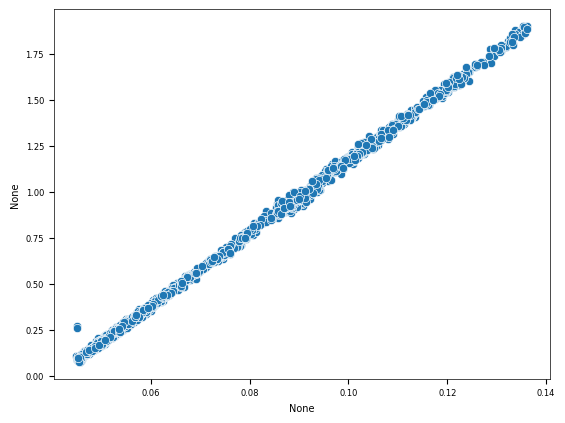

In [16]:
plt.figure()
sns.scatterplot(x = msd.detach(),y = density.detach(),)

RuntimeError: Can't call numpy() on Tensor that requires grad. Use tensor.detach().numpy() instead.

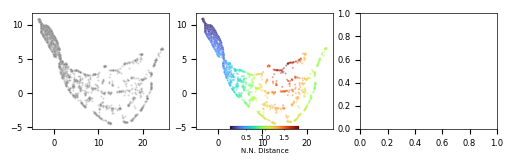

In [17]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(6, 1.5))

gs = gridspec.GridSpec(1, 3)

# Assign your subplots to the grid slots, skipping the spacer slot (index 2)
ax1 = plt.subplot(gs[0])
ax2 = plt.subplot(gs[1])
# Index 2 is intentionally left blank as a gap
ax3 = plt.subplot(gs[2])



z_neurons = umap.UMAP(densmap=True,dens_lambda=2,n_neighbors=500).fit_transform(x.detach())




# Gray
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], color='gray', s=2, alpha=.35,ax=ax1)

# NN Distance
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=density.detach(),cmap  = 'turbo', s=2, alpha=.5,ax=ax2)
cax = inset_axes(
        ax2, width="50%", height="2%",
        loc="lower center", borderpad=0
    )

norm = plt.Normalize(density.min(), density.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("N.N. Distance", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)

# MSD
vmin_msd, vmax_msd = np.percentile(msd, [1, 99])
range_msd = vmax_msd - vmin_msd
vmin_msd -= 0.1 * range_msd
vmax_msd += 0.1 * range_msd
sns.scatterplot(x=z_neurons[:, 0], y=z_neurons[:, 1], c=msd,cmap='turbo', s=2, alpha=.5,ax=ax3,vmin=vmin_msd, vmax=vmax_msd)
cax = inset_axes(
        ax3, width="50%", height="2%",
        loc="lower center", borderpad=0
    )
norm = plt.Normalize(msd.min(), msd.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("MSD", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)





# 4. Global figure customizations
#fig.suptitle("Main Title for All 5 Subplots", fontsize=18, fontweight="bold", y=1.05)

# Automatically adjusts subplot parameters so that the labels don't overlap
for ax in [ax1,ax2,ax3]:
    for spine in ax.spines.values():
        spine.set_visible(False)

    # 2. Hide the tick marks and tick numbers
    ax.set_xticks([])
    ax.set_yticks([])

    # 3. Add your labels normally
    ax.set_xlabel('')
    ax.set_ylabel('')



ax1.set_xlabel('DensMAP 1',fontsize = 5)
ax1.set_ylabel('DensMAP 2',fontsize = 5)



#fig.subplots_adjust(wspace=0.2)

# Figure labels
ax1.text(-0.05, 1., 'a', transform=ax1.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')
ax2.text(-0.05, 1, 'b', transform=ax2.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')
ax3.text(-0.05, 1, 'c', transform=ax3.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')

# Subfigure titles
ax1.set_title('CP',fontsize = 6,fontname = 'Helvetica',alpha = .5)

# axes[3].set_title('Rotation 1',fontsize = 6,fontname = 'Helvetica')
# 5. Display or save the plot
#plt.tight_layout()
plt.savefig("CPRotations.png", bbox_inches='tight', dpi=300)



In [ ]:
def get_curvature(model,dt,steps):
    """
    Computes curvature for each neuron at each time step and trial.
    Curvature = (h_dot_i)^2 * f''(h_i)
    where h_i is the pre-activation input to neuron i.
    """

    y = model(dt,steps)
    h = model.recurrent_layer(y)

    # 3. Compute f''(h) for softplus
    beta = model.beta
    f_prime = torch.sigmoid(beta * h)
    f_double_prime = beta * f_prime * (1 - f_prime)

    # 4. Compute y_dot analytically
    y_dot = -y + model.activation(h)

    # 5. Compute h_dot analytically
    h_dot = torch.matmul(y_dot, model.recurrent_layer.weight.t())

    # 6. Compute curvature = (h_dot)^2 * f''(h)
    curvature = (h_dot**2) * f_double_prime

    return curvature.detach().cpu().numpy(),f_double_prime.detach().cpu().numpy()

def calculate_hdot(model,dt,steps):
    """
    Calculates h_dot for each neuron, time and trial.
    Returns an array of shape (trials, time, neurons).
    """
    with torch.no_grad():
        # 1. Forward pass to get states y
        y = model(dt,steps)
        # 2. Compute pre-activation h = W_rec * y + W_in * u + b
        h = model.recurrent_layer(y)
        # 3. Compute y_dot analytically
        ydot =  -y + model.activation(h)
        # 4. Compute h_dot analytically
        hdot = torch.matmul(ydot, model.recurrent_layer.weight.t())
    return hdot.cpu().numpy()


def calculate_msd(model, dt,steps):
    """
    Calculates mean standardized derivatives for each neuron, time and trial.
    Returns an array of shape (trials, time, neurons).
    """
    model.eval()
    with torch.no_grad():
        # 1. Forward pass to get states y
        y = model(dt,steps)

        # 2. Compute temporal derivative dy/dt using system dynamics

        h = model.recurrent_layer(y)
        ydot =  (-y + model.activation(h))

        # 3. Z-score normalization
        std = y.std(dim=(0, 1), keepdim=True)
        epsilon = 1e-8

        # 4. Result: dot y_i / sigma_i
        msd = ydot / (std + epsilon)

    return msd.cpu().numpy()

TypeError: mean() received an invalid combination of arguments - got (out=NoneType, dtype=NoneType, axis=int, ), but expected one of:
 * (*, torch.dtype dtype = None)
 * (tuple of ints dim, bool keepdim = False, *, torch.dtype dtype = None)
 * (tuple of names dim, bool keepdim = False, *, torch.dtype dtype = None)


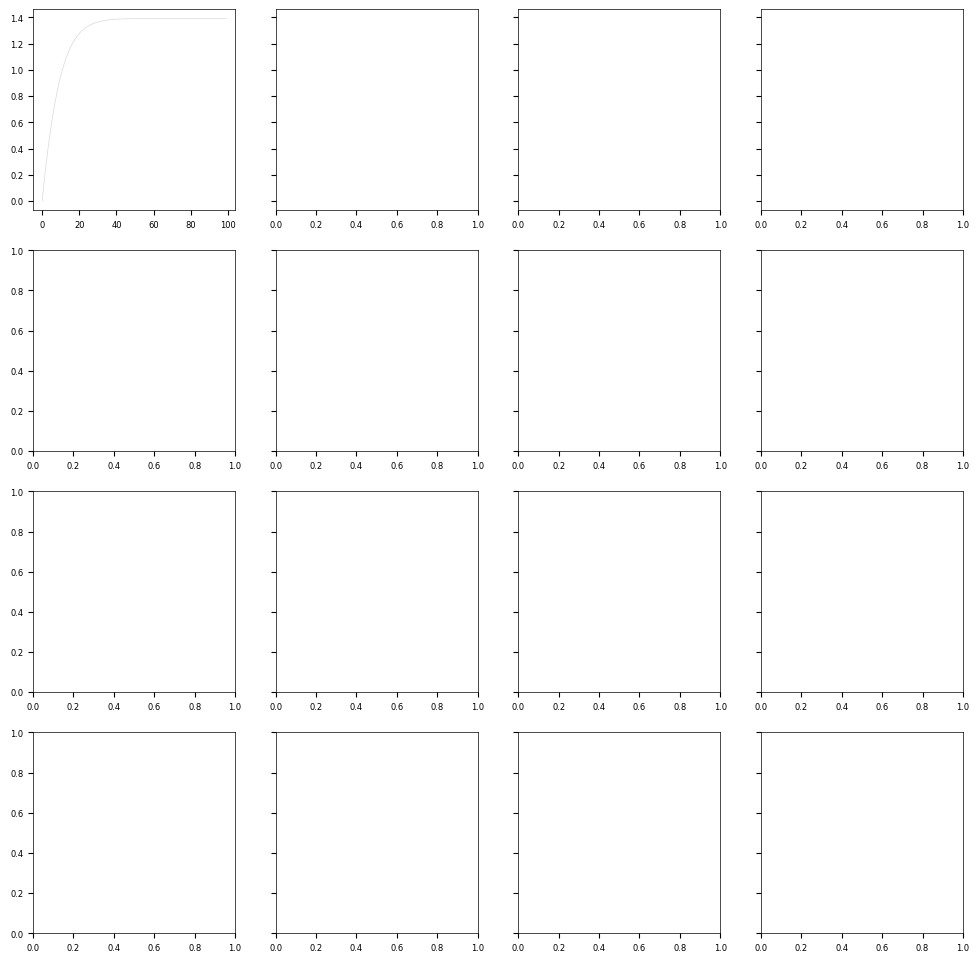

In [20]:
# Time series plots


# %%
def plot_time_series(model,dt,steps):

    msd_per_neuron = calculate_msd(model, dt,steps)
    msd_per_neuron = np.mean(np.abs(msd_per_neuron),axis=(0,1))
    n_neurons = msd_per_neuron.shape[0]

    # Group neurons into 4 groups based on MSD quantiles
    n_groups = 4
    msd_sorted_indices = np.argsort(msd_per_neuron)
    group_size = n_neurons // n_groups
    groups = [msd_sorted_indices[i*group_size:(i+1)*group_size] for i in range(n_groups)]
    # Handle the remainder if any by adding it to the last group
    if n_neurons % n_groups != 0:
        groups[-1] = np.concatenate([groups[-1], msd_sorted_indices[n_groups*group_size:]])

    # Simulation parameters
    n_t = steps

    # Check if stim_on/stim_off are defined, if not use defaults
    s_on = globals().get('stim_on', 0.25)
    s_off = globals().get('stim_off', 0.75)

    stim_on_time = n_t * s_on
    stim_off_time = n_t * s_off

    # Calculate simulated metrics
    # shape (trials, time, neurons)
    msd_val_sim = calculate_msd(model,dt,steps)
    hdot_val_sim = calculate_hdot(model,dt,steps)
    curvature_val,_ = get_curvature(model,dt,steps)

    # Compute h values to find zero crossings
    with torch.no_grad():
        y_sim = model(dt,steps)
        h_vals_sim = model.recurrent_layer(y_sim)
        y_sim = y_sim.cpu().numpy()

    time_axis = np.arange(steps)

    fig, axes = plt.subplots(4, 4, figsize=(12, 12), sharey='row')

    # Rows: Response, Curvature, MSD, h_dot
    # Columns: MSD Groups
    for i, group_indices in enumerate(groups):
        # Mean MSD for this group
        group_msd = np.mean(msd_per_neuron[group_indices])

        # Row 0: Response
        ax = axes[0, i]
        # Mean response across neurons for each trial
        trial_mean_y = np.mean(y_sim[:, :, group_indices], axis=2)
        for trial_idx in range(trial_mean_y.shape[0]):
            ax.plot(time_axis, trial_mean_y[trial_idx, :], color='gray', alpha=0.3, lw=0.5)
            # Note: zero crossings for the group mean might be different from individual neurons
            h_trial_mean = np.mean(h_vals_sim[trial_idx, :, group_indices], axis=1)
            crossings = np.where(np.diff(np.sign(h_trial_mean)) != 0)[0]
            # Ensure crossings don't exceed array bounds
            crossings = crossings[crossings < len(time_axis)]
            if len(crossings) > 0:
                ax.scatter(time_axis[crossings], trial_mean_y[trial_idx, crossings], color='black', s=2, zorder=3)
        mean_y = np.mean(trial_mean_y, axis=0)
        ax.plot(time_axis, mean_y, color='darkred', lw=1.5)
        ax.set_title(f"Group {i+1}\nMean MSD: {group_msd:.4f}")
        ax.set_xlabel("Time (s)")
        if i == 0:
            ax.set_ylabel("Response") # Was incorrectly "Curvature" in original row 0
        ax.tick_params(axis='both', labelsize=8)
        sns.despine(ax=ax)

        # Row 1: Curvature
        ax = axes[1, i]
        trial_mean_curvature = np.mean(curvature_val[:, :, group_indices], axis=2)
        for trial_idx in range(trial_mean_curvature.shape[0]):
            ax.plot(time_axis, trial_mean_curvature[trial_idx, :], color='gray', alpha=0.3, lw=0.5)
            h_trial_mean = np.mean(h_vals_sim[trial_idx, :, group_indices], axis=1)
            crossings = np.where(np.diff(np.sign(h_trial_mean)) != 0)[0]
            crossings = crossings[crossings < len(time_axis)]
            if len(crossings) > 0:
                ax.scatter(time_axis[crossings], trial_mean_curvature[trial_idx, crossings], color='black', s=2, zorder=3)
        mean_curvature = np.mean(trial_mean_curvature, axis=0)
        ax.plot(time_axis, mean_curvature, color='darkred', lw=1.5)
        ax.set_xlabel("Time (s)")
        if i == 0:
            ax.set_ylabel("Curvature")
        ax.tick_params(axis='both', labelsize=8)
        sns.despine(ax=ax)

        # Row 2: MSD
        ax = axes[2, i]
        trial_mean_msd = np.mean(msd_val_sim[:, :, group_indices], axis=2)
        for trial_idx in range(trial_mean_msd.shape[0]):
            ax.plot(time_axis, trial_mean_msd[trial_idx, :], color='gray', alpha=0.3, lw=0.5)
            h_trial_mean = np.mean(h_vals_sim[trial_idx, :, group_indices], axis=1)
            crossings = np.where(np.diff(np.sign(h_trial_mean)) != 0)[0]
            crossings = crossings[crossings < len(time_axis)]
            if len(crossings) > 0:
                ax.scatter(time_axis[crossings], trial_mean_msd[trial_idx, crossings], color='gray', s=2, zorder=3)
        mean_msd_plot = np.mean(trial_mean_msd, axis=0)
        ax.plot(time_axis, mean_msd_plot, color='darkred', lw=1.5)
        ax.set_xlabel("Time (s)")
        if i == 0:
            ax.set_ylabel("dot y_i / std(y_i)")
        ax.tick_params(axis='both', labelsize=8)
        sns.despine(ax=ax)

        # Row 3: h_dot
        ax = axes[3, i]
        trial_mean_hdot = np.mean(hdot_val_sim[:, :, group_indices], axis=2)
        for trial_idx in range(trial_mean_hdot.shape[0]):
            ax.plot(time_axis, trial_mean_hdot[trial_idx, :], color='gray', alpha=0.3, lw=0.5)
            h_trial_mean = np.mean(h_vals_sim[trial_idx, :, group_indices], axis=1)
            crossings = np.where(np.diff(np.sign(h_trial_mean)) != 0)[0]
            crossings = crossings[crossings < len(time_axis)]
            if len(crossings) > 0:
                ax.scatter(time_axis[crossings], trial_mean_hdot[trial_idx, crossings], color='black', s=2, zorder=3)
        mean_hdot = np.mean(trial_mean_hdot, axis=0)
        ax.plot(time_axis, mean_hdot, color='darkred', lw=1.5)
        ax.set_xlabel("Time (s)")
        if i == 0:
            ax.set_ylabel("dot h_i")
        ax.tick_params(axis='both', labelsize=8)
        sns.despine(ax=ax)

    # Add stimulus window and y=0 line to all subplots
    for ax in axes.flat:
        if 'stim_on_time' in locals() and 'stim_off_time' in locals():
            ax.axvspan(stim_on_time, stim_off_time, color='gray', alpha=0.3, label='stim')
        ax.axhline(0, color='gray', linestyle='--', alpha=0.3)

    plt.tight_layout()
    return fig



fig = plot_time_series(net,dt,100)
plt.savefig("../Figures/NonlinearTask_NeuronCurvatureTrials.png", bbox_inches='tight', dpi=300, transparent=True)
plt.show()





# %%



In [22]:
curvature,filter = get_curvature(net,dt,100)

In [23]:
curvature.shape

(1, 100, 2000)

In [25]:
neuron_index = torch.argsort(msd)[0]

In [28]:
plt.figure()
plt.plot(curvature[1,:,neuron_index])
plt.plot(curvature[1,:,torch.argsort(msd)[-1]])

IndexError: index 1 is out of bounds for axis 0 with size 1

<Figure size 640x480 with 0 Axes>